# Day 4 — One concept, from birth to action

Yesterday's agents each own a belief on the shared graph. Today we follow one belief through its
life, look at what it stands on, and then let it act: what is a look worth, and who chooses.

**Life cycle: how a belief begins and ends.**
1. **Birth** (in class: Exercise 1; Exercise 2 at home). An object is born by comparing two worlds in nats, not by counting detections.
2. **Absence** (in class: Exercises 3–4). A miss removes an object only where the object would have been seen.
3. **Forgetting** (at home: Exercises 5–6). Replace a constant process noise by an inferred volatility.

**Geometry: what a belief stands on.**
4. **The room** (optional, not in the lecture: Exercises 7–11). Find the room's walls in a scan, with no labels and no map.
5. **The pose** (in class: Exercise 12; Exercise 13 at home). Drive, and keep a calibrated belief about where you are.
6. **Symmetry** (optional: Exercise 14). Find the place where gradient descent cannot help.
7. **The common-mode ceiling** (optional: Exercise 15). See how little a thousand points teach when they share one error.
8. **Two regimes** (reading). The thesis calls 4 the **acquisition** regime, where the room is a variable,
   and 5 the **operating** regime, where the room is a constant.

**Action: what a belief offers.**
9. **Where to look** (in class: Exercises 16 and 18; 17 and 19 at home). One belief, a few candidate
   viewpoints, expected information against the price of a trip.
10. **Priced offers** (at home: Exercises 20–22). Many beliefs on the shared graph, one body. Producers
   publish, the controller chooses, and hand-offs happen without a rule.

In class: Exercises 1, 3, 4, 12, 16 and 18, about 55 minutes. The sections run on their own:
skip the optional ones. Route following and the occupancy-grid explorer are in `day4_extra.ipynb`.

In [1]:
import sys
from pathlib import Path

LABS = Path.cwd() if (Path.cwd() / "toyworld").exists() else Path.cwd().parent
sys.path.insert(0, str(LABS))

import matplotlib.pyplot as plt
import numpy as np

from toyworld import Gaussian, Lidar, Robot, draw, laplace, se2, two_room_apartment
from toyworld.geometry import distance_to_polygon, polygon_area, polygon_iou
from toyworld.robot import Body, predict

rng = np.random.default_rng(0)
world = two_room_apartment()
lidar = Lidar(n_beams=360, sigma=0.02, max_range=12.0)
SIGMA = 0.02
TRUE0 = np.array([1.0, 0.6, 0.3])       # where the robot starts in the world; ground truth, for grading only

## 1. Birth: a belief begins as a model comparison (in class)

A run of detections has appeared near the bottle. Does the room contain a new object, or is this
clutter? A tracker would count: *three detections close together, and the object exists*. The
generative model asks a different question: which of two worlds, one with this object and one
without it, explains these detections in fewer nats?

- **Without it**, each detection is clutter, uniform over the room: $p(z) = 1/A$.
- **With it**, each detection scatters about an unknown centre, $z_t\sim\mathcal N(\theta,\sigma_t^2 I)$,
  and $\theta$ has a broad prior over the room.

Both worlds also carry a prior probability of the object existing, $\pi$. Then

$$\Delta F = F_\text{with} - F_\text{without}, \qquad F_\text{with} =
  -\ln\pi + F_\text{Laplace}, \qquad F_\text{without} = -\ln(1-\pi) + n\ln A,$$

and the object is warranted when $\Delta F<0$. Note that each detection carries its **own** $\sigma_t$:
a detector reports how far it should be trusted, and the comparison reads that.

**Exercise 1.** Write `delta_F`, using Day 2's `laplace` for $F_\text{Laplace}$.

In [2]:
AREA, P_EXIST = 24.0, 0.1                                     # the living room's area; prior that a new object is here
CLASS_PRIOR = Gaussian([3.0, 2.0], np.diag([3.0 ** 2, 2.0 ** 2]))  # "somewhere in this room"
THETA = np.array([4.6, 0.9])


def detection_residual(z):
    return lambda th: (z - th).ravel()


def detection_jacobian(z):
    return lambda th: -np.tile(np.eye(2), (len(z), 1))


def delta_F(z, sigma):
    """F(world with the object) - F(world without it), for detections z (n, 2) with sd sigma."""
    s = np.repeat(np.broadcast_to(sigma, (len(z),)), 2)         # one sd per residual
    fit = laplace(detection_residual(z), z.mean(axis=0), s, prior=CLASS_PRIOR, jacobian=detection_jacobian(z))
    F_with = fit.free_energy - np.log(P_EXIST)
    F_without = len(z) * np.log(AREA) - np.log(1 - P_EXIST)
    return F_with - F_without


SOURCES = {                                       # what generates the detections, and the sd the detector reports
    "sharp views":   (lambda r, n: THETA + 0.05 * r.standard_normal((n, 2)), 0.05),
    "distant views": (lambda r, n: THETA + 0.30 * r.standard_normal((n, 2)), 0.30),
    "reflections":   (lambda r, n: THETA + r.uniform(-0.6, 0.6, (n, 2)), 0.10),
}
r_a = np.random.default_rng(1)
traces = {}
for name, (gen, sd) in SOURCES.items():
    z = gen(r_a, 10)
    traces[name] = [delta_F(z[:k], sd) for k in range(1, 11)]
    print(f"{name:14s} dF after 1..10 detections: " + " ".join(f"{d:6.1f}" for d in traces[name]))

sharp views    dF after 1..10 detections:    2.9   -2.6   -9.2  -15.7  -22.8  -29.9  -36.6  -43.6  -50.6  -57.5
distant views  dF after 1..10 detections:    3.0    0.7    2.8   -0.6   -3.8   -4.7   -5.6   -8.8  -11.0  -14.6
reflections    dF after 1..10 detections:    3.0   12.5    9.1   19.4   18.1   21.6   22.7   50.0   57.2   57.8


**Exercise 2.** The streak rule says: a detection *feeds* the candidate when it falls within 0.6 m
of the candidate's running mean, and the object is born once three detections have fed it. Over
300 runs, compute how often each rule accepts:
- two sharp views of a real object ($n=2$);
- ten reflections scattered over a 1.2 m patch ($n=10$).

Take the $\Delta F$ decision on all the detections of the run.

In [3]:
def streak_length(z, gate=0.6):
    fed = [z[0]]
    for p in z[1:]:
        if np.linalg.norm(p - np.mean(fed, axis=0)) < gate:
            fed.append(p)
    return len(fed)


birth_rates = {}
for name, n in (("sharp views", 2), ("reflections", 10)):
    gen, sd = SOURCES[name]
    runs = [gen(np.random.default_rng(seed), n) for seed in range(300)]
    streak = np.mean([streak_length(z) >= 3 for z in runs])
    model = np.mean([delta_F(z, sd) < 0 for z in runs])
    birth_rates[name] = (streak, model)
    print(f"{name:14s} n={n:2d}:  streak of 3 accepts {streak:5.1%}   dF<0 accepts {model:5.1%}")

sharp views    n= 2:  streak of 3 accepts  0.0%   dF<0 accepts 98.0%
reflections    n=10:  streak of 3 accepts 93.7%   dF<0 accepts  0.0%


**Questions.**
- Change the class prior to one centred on the bottle with a 10 cm spread. What happens to the number
  of detections needed, and which term of $F$ changed?
- The streak is compared against a *number of frames*; $\Delta F$ is in nats. Name one decision that
  can be traded against $\Delta F$ and cannot be traded against a streak.

*Answers.*
- The complexity term: squeezing a broad prior down to a posterior costs nats, and a tight prior has
  little squeezing left to pay for, so one detection can be enough. A strong prior makes an object
  cheap to believe in, which is exactly what a class prior is for.
- Anything else in nats: the existence log-odds that will later decide its removal, a merge of two
  instances, the expected free energy of going to look. The thesis's deployed tracker still uses a
  weighted streak, and says plainly that this is a threshold that should not be one
  (agents_life_cycle.tex, "What the surrogate costs").

## 2. Absence: a miss is evidence only where the object would have been seen (in class)

Every belief carries one number for whether it exists: a log-odds $L$. A frame can say one of three
things about it:

| observation | verdict |
|---|---|
| a return inside the believed volume | **confirms** |
| predicted visible, and nothing there | **removes** |
| occluded, out of view, or too far to tell | **holds** |

The robot below tours the living room with a camera-like sensor (90° field of view) whose detector
fires on a beam landing on an object with probability $p_b(r) = e^{-(r/3\,\text{m})^2}$. It holds five
beliefs: a **table**, a small **bottle** and a **plant** tucked behind the table, all really there; a
**chair** that is really there but in the next room; and a **vase** that somebody took away before
the tour began.

**Exercise 3.** Write `predicted_beams`: which beams would land on this belief first, given the
other believed objects and, when `use_walls` is true, the walls? (`raycast` returns, for each beam,
the index of the first thing hit; indices past `len(segs)` are the discs, in order.)

In [4]:
from toyworld.lidar import raycast  # noqa: E402
from toyworld.world import Thing  # noqa: E402


class Believed:
    def __init__(self, name, centre, radius):
        self.name, self.centre, self.radius = name, np.array(centre, float), radius


world_b = two_room_apartment()
world_b.things.append(Thing("plant", "disc", [0.9, 3.3, 0.0], (0.15,)))
ALL_SEGS, SEG_LABELS = world_b.segments()
WALLS = ALL_SEGS[SEG_LABELS == "wall"]
BELIEFS = [Believed("table", [2.2, 2.6], 0.6), Believed("bottle", [4.6, 0.9], 0.08), Believed("plant", [0.9, 3.3], 0.2),
           Believed("chair", [8.4, 3.6], 0.3), Believed("vase", [5.0, 3.3], 0.15)]
camera = Lidar(n_beams=120, fov=np.deg2rad(90), sigma=0.02, max_range=8.0)
waypoints = np.array([[1.2, 0.8], [4.8, 0.8], [5.2, 2.0], [4.2, 3.4], [3.6, 1.4], [1.2, 1.2]])
TOUR = []
for i in range(240):                                    # slide along the waypoints while the head sweeps round
    s = i / 240 * (len(waypoints) - 1)
    k = int(s)
    p = waypoints[k] + (s - k) * (waypoints[k + 1] - waypoints[k])
    TOUR.append(np.array([p[0], p[1], 0.11 * i]))


def predicted_beams(b, pose, beliefs, use_walls=True):
    """Boolean (B,): the beams that would land on belief b before anything else. Also returns the ranges."""
    angles = pose[2] + camera.angles()
    dirs = np.stack([np.cos(angles), np.sin(angles)], axis=1)
    centres = np.array([x.centre for x in beliefs])
    radii = np.array([x.radius for x in beliefs])
    segs = WALLS if use_walls else np.zeros((0, 2, 2))
    d, idx = raycast(pose[:2], dirs, segs, centres, radii)
    on_b = (idx == len(segs) + beliefs.index(b)) & (d <= camera.max_range)
    return on_b, d

Now the update. How far a miss should count is $P(\text{detect}\mid\text{present})$, the probability that
the sensor would have fired had the object been there,

$$ P(\text{detect}) = 1-\prod_{\text{beams}}\big(1-p_b(r)\big). $$

One frame's evidence **saturates**: no single frame may move $L$ by more than `LOCC`, because the
points of one frame are not independent. The question that matters is on which side of that ceiling
the weight goes.

**Exercise 4.** Write `existence_step` for the three verdicts. In the correct rule the absence
increment is $-P(\text{detect})\cdot\min(c\,n_\text{pred},\ell_\text{occ})$: saturate first, weight
afterwards. With `weight_count=True`, apply the weight to the count instead, before the ceiling.

a 2%-resolvable view: saturate then weight drops L by 0.0079; weight the count drops it by 0.4000



evidence           removed: vase (frame 68)


no walls           removed: vase (frame 68), chair (frame 174)


weight the count   removed: vase (frame 13)
miss counter       removed: vase (frame 14), bottle (frame 22), chair (frame 24), plant (frame 32), table (frame 44)


Text(0.5, 1.0, 'the evidence rule')

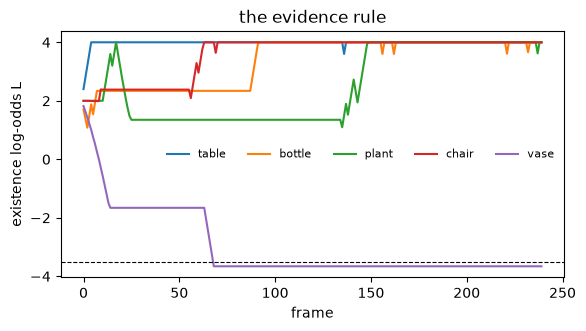

In [5]:
LOCC, PER_BEAM, L0, LMAX, L_DEAD = 0.4, 1.0, 2.0, 4.0, -3.5
R_SEE = 3.0


def p_beam(r):
    return np.exp(-(r / R_SEE) ** 2)


def existence_step(L, n_hit, on_b, ranges, weight_count=False):
    n_pred = int(on_b.sum())
    if n_hit > 0:
        return min(L + min(PER_BEAM * n_hit, LOCC), LMAX)
    if n_pred == 0:
        return L
    p_detect = 1.0 - np.prod(1.0 - p_beam(ranges[on_b]))
    if weight_count:
        drop = min(p_detect * PER_BEAM * n_pred, LOCC)
    else:
        drop = p_detect * min(PER_BEAM * n_pred, LOCC)
    return max(L - drop, -LMAX)


def run_tour(rule, seed=0):
    """rule: 'evidence', 'no walls', 'weight the count' or 'miss counter'. Returns L traces and deaths."""
    r = np.random.default_rng(seed)
    L = {b.name: L0 for b in BELIEFS}
    silent = {b.name: 0 for b in BELIEFS}
    dead, trace = {}, []
    for t, pose in enumerate(TOUR):
        scan = camera.scan(world_b, pose, r)
        h = scan.hit & (scan.labels != "wall")
        pts = se2.transform_points(pose, np.stack([scan.ranges[h] * np.cos(scan.angles[h]),
                                                   scan.ranges[h] * np.sin(scan.angles[h])], axis=1))
        pts = pts[r.random(len(pts)) < p_beam(scan.ranges[h])]    # the detector misses far objects
        alive = [b for b in BELIEFS if b.name not in dead]
        for b in alive:
            n_hit = int((np.linalg.norm(pts - b.centre, axis=1) < b.radius + 0.25).sum()) if len(pts) else 0
            on_b, d = predicted_beams(b, pose, alive, use_walls=rule != "no walls")
            if rule == "miss counter":
                silent[b.name] = 0 if n_hit else silent[b.name] + 1
                if silent[b.name] >= 15:
                    dead[b.name] = t
                continue
            L[b.name] = existence_step(L[b.name], n_hit, on_b, d, weight_count=rule == "weight the count")
            if L[b.name] <= L_DEAD:
                dead[b.name] = t
        trace.append(dict(L))
    return trace, dead


# one frame, one object: a large object 40 beams wide, each beam only 0.05% likely to fire
on_far, ranges_far = np.ones(40, bool), np.full(40, 3.0 * np.sqrt(-np.log(0.0005)))
p_far = 1 - np.prod(1 - p_beam(ranges_far))
drop_right = L0 - existence_step(L0, 0, on_far, ranges_far)
drop_count = L0 - existence_step(L0, 0, on_far, ranges_far, weight_count=True)
print(f"a {p_far:.0%}-resolvable view: saturate then weight drops L by {drop_right:.4f}; "
      f"weight the count drops it by {drop_count:.4f}\n")

tour_results = {}
for rule in ("evidence", "no walls", "weight the count", "miss counter"):
    trace, dead = run_tour(rule)
    tour_results[rule] = (trace, dead)
    print(f"{rule:18s} removed: " + (", ".join(f"{n} (frame {t})" for n, t in dead.items()) or "nothing"))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for b in BELIEFS:
    ax.plot([s[b.name] for s in tour_results["evidence"][0]], label=b.name)
ax.axhline(L_DEAD, color="k", lw=0.8, ls="--"); ax.set_xlabel("frame"); ax.set_ylabel("existence log-odds L")
ax.legend(ncol=5, frameon=False, fontsize=8); ax.set_title("the evidence rule")

**Questions.**
- Compare the rules. Which objects does each remove, and why? The rule that weights the count removes
  the right object: what is wrong with it? (Look at the frame numbers and the one-frame line above.)
- The correct rule never removes an object that can never be probed. A constant decay added under
  $P(\text{detect})$ would. Why does the thesis forbid that, and what does it do instead?

*Answers.*
- **Miss counter:** it deletes everything the head has not looked at for 15 frames; it runs on the
  agent's clock. **No walls:** the chair projects into view through the wall, finds no detection,
  and votes for its own removal: the bug the thesis's agents suffered three times. **Weighting the
  count:** it happens to reach the right verdict here, five times sooner, because a far view
  counts as fully as a near one. A 2%-resolvable view with many beams still reaches the ceiling: the
  weight has changed nothing. Only a weight applied after the ceiling can act.
- A decay is removal without evidence, on the agent's clock. The contract routes an unresolvable
  instance to a *verification pull*: it raises the expected information of a view of it, the robot
  goes to look, and the existence belief decides on evidence obtained for the purpose. Uncertainty you
  cannot resolve from here is a reason to move, not a reason to forget.

## 3. Forgetting: how fast does *this* object change? (at home)

A static object is usually tracked by adding a constant process noise every frame,
$\Sigma \leftarrow \Sigma + Q$, whether or not anything was seen. That makes two predictions, neither
of which depends on how long the object has been known:

- **unobserved**, the variance grows linearly: $\Sigma(n)=\Sigma_0+Qn$;
- **observed**, precision does not accumulate: it stops at a floor $\sigma_\text{steady}\approx(Q/i)^{1/4}$,
  where $i$ is the information of one frame.

The cure replaces the constant by an inferred, per-object quantity $Q = e^{\zeta}$, driven by how
surprised the belief is. With innovation $\nu$ and its predicted variance $S$, the normalised surprise is
$d = \nu^2/S$, and

$$\zeta \leftarrow \zeta + \eta\Big(\tfrac12\big(\tilde d - \mathbb E[\tilde d\,]\big)
   - \frac{\zeta-\zeta_0}{\sigma_\zeta^2}\Big),\qquad
   \tilde d = \frac{(\nu_0+1)\,d}{\nu_0+d}. $$

The first term compares the surprise actually seen with the surprise a calibrated model expects. The
last is the hyperprior's pull-back, which keeps $\zeta$ recoverable. $\tilde d$ is the surprise of
a Student-$t$ innovation: it saturates, so that **one outrageous frame moves $\zeta$ by a bounded
amount**, and only a *run* of surprises moves it far.

The stream below is one coordinate of a table: 400 s at 10 Hz, one spurious mask 40 cm off at frame
4000, unobserved from frame 5000 to 5600, genuinely moved 50 cm at frame 6000.

**Exercise 5.** Fill in the Kalman step and the $\zeta$ update.

E[d~] under a calibrated model = 0.786
predicted floor (Q/i)^(1/4) = 10.0 mm
constant Q  sd before the spurious mask   9.4 mm | moved by it  92.4 mm, 10 frames on  16.9 mm | sd after the 60 s gap 122.8 mm | adapts to the real move in 9 frames
inferred Q  sd before the spurious mask   6.5 mm | moved by it  44.0 mm, 10 frames on  19.2 mm | sd after the 60 s gap  45.4 mm | adapts to the real move in 15 frames


Text(0.5, 0, 'frame')

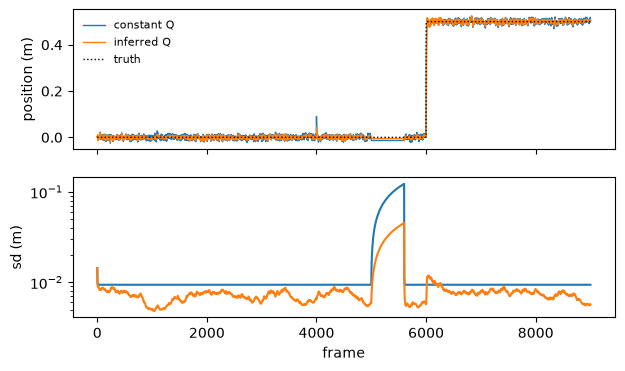

In [6]:
T_FRAMES = 9000
R_FRAME = 0.02 ** 2
Q_CONST = 2.5e-5                                    # (0.005 m)^2 per frame, the deployed process noise
ZETA0, SIGMA_ZETA, ETA, NU0 = np.log(Q_CONST), 10.0, 0.1, 4.0
_d = np.linspace(1e-6, 60, 600000)
_chi2 = np.exp(-_d / 2) / np.sqrt(2 * np.pi * _d)
E_DTILDE = np.sum((NU0 + 1) * _d / (NU0 + _d) * _chi2) * (_d[1] - _d[0])
print(f"E[d~] under a calibrated model = {E_DTILDE:.3f}")

r_c = np.random.default_rng(0)
true_c = np.zeros(T_FRAMES); true_c[6000:] = 0.5
z_c = true_c + np.sqrt(R_FRAME) * r_c.standard_normal(T_FRAMES); z_c[4000] += 0.4
seen = np.ones(T_FRAMES, bool); seen[5000:5600] = False


def track(z, seen, infer):
    """Run the filter. infer=False: constant Q. Returns arrays mu, Sigma, zeta."""
    mu, Sig, zeta = z[0], R_FRAME, ZETA0
    out = []
    for t in range(len(z)):
        Q = Q_CONST if not infer else np.exp(zeta)
        P = Sig + Q
        if seen[t]:
            S = P + R_FRAME
            nu = z[t] - mu
            K = P / S
            mu, Sig = mu + K * nu, (1 - K) * P
            if infer:
                d = nu ** 2 / S
                d_tilde = (NU0 + 1) * d / (NU0 + d)
                zeta += ETA * (0.5 * (d_tilde - E_DTILDE) - (zeta - ZETA0) / SIGMA_ZETA ** 2)
        else:
            Sig = P
        out.append((mu, Sig, zeta))
    return np.array(out).T


mu_q, S_q, _ = track(z_c, seen, infer=False)
mu_v, S_v, zeta_v = track(z_c, seen, infer=True)


def adapt_time(mu):
    return int(np.argmax(np.abs(mu[6000:] - 0.5) < 0.05))


print(f"predicted floor (Q/i)^(1/4) = {(Q_CONST * R_FRAME) ** 0.25 * 1000:.1f} mm")
for name, mu, Sig in (("constant Q", mu_q, S_q), ("inferred Q", mu_v, S_v)):
    print(f"{name:11s} sd before the spurious mask {np.sqrt(Sig[3999]) * 1000:5.1f} mm | "
          f"moved by it {abs(mu[4000] - mu[3999]) * 1000:5.1f} mm, 10 frames on {abs(mu[4010] - mu[3999]) * 1000:5.1f} mm | "
          f"sd after the 60 s gap {np.sqrt(Sig[5599]) * 1000:5.1f} mm | adapts to the real move in {adapt_time(mu)} frames")

fig, axes = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
axes[0].plot(mu_q, label="constant Q", lw=1); axes[0].plot(mu_v, label="inferred Q", lw=1); axes[0].plot(true_c, "k:", lw=1, label="truth")
axes[0].legend(frameon=False, fontsize=8); axes[0].set_ylabel("position (m)")
axes[1].semilogy(np.sqrt(S_q), label="constant Q"); axes[1].semilogy(np.sqrt(S_v), label="inferred Q"); axes[1].set_ylabel("sd (m)"); axes[1].set_xlabel("frame")

**Exercise 6.** Feed `track` a stream with a constant **bias**: every frame reads 5 cm high, from the
start, with the same noise. Report the final error and the final standard deviation of both filters,
and their ratio. What has the inferred volatility done?

In [7]:
z_bias = 0.05 + np.sqrt(R_FRAME) * np.random.default_rng(2).standard_normal(T_FRAMES)
for name, infer in (("constant Q", False), ("inferred Q", True)):
    mu, Sig, _ = track(z_bias, np.ones(T_FRAMES, bool), infer)
    err = np.abs(mu[-2000:]).mean()
    print(f"{name:11s} mean error {err * 1000:5.1f} mm, claimed sd {np.sqrt(Sig[-2000:].mean()) * 1000:5.2f} mm: "
          f"{err / np.sqrt(Sig[-2000:].mean()):.1f} sigma out")

constant Q  mean error  50.8 mm, claimed sd  9.40 mm: 5.4 sigma out
inferred Q  mean error  50.9 mm, claimed sd  6.67 mm: 7.6 sigma out


*Answer.* A bias is perfectly consistent, so the surprise stays small and nothing raises $\zeta$:
both filters report a few millimetres of uncertainty while being wrong by the whole 5 cm, and the
inferred one is, if anything, more confident. The volatility cannot see a bias; only an error model can. That is why the thesis says volatility
and the common-mode $\Sigma_\delta$ must be reasoned about together, and it is the same reason a shared
bias, unlike a symmetric error, must be gated rather than down-weighted.

## 4. The first belief born: acquiring the room (optional)

The room is a belief with a birth of its own: nothing in the first scan says how many walls there
are. Yesterday the robot was told which points belonged to the wall, and knew its pose; here it
knows neither.

### 4.1 Whose frame?

The robot has no map, so there is no "world" frame it could report a pose in. The only frame
available is its own frame at the moment it starts. That choice is a **gauge**: a convention
that no measurement could ever fix, because the data would be identical in any other frame.
From here on, the **map frame is the robot's frame at t = 0**. The true starting pose `TRUE0`
is used only for grading.

Text(0.5, 1.0, 'what the robot has: one scan, in its own frame')

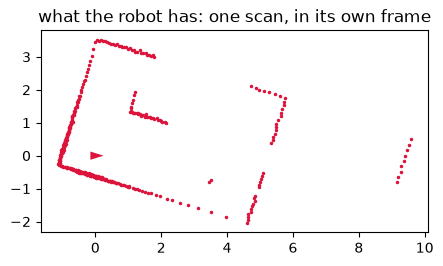

In [8]:
scan0 = lidar.scan(world, TRUE0, rng)
P0 = scan0.points()                      # robot frame at t=0  ==  map frame

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(P0[:, 0], P0[:, 1], ".", ms=3, color="crimson")
draw.robot([0, 0, 0], ax)
ax.set_aspect("equal"); ax.set_title("what the robot has: one scan, in its own frame")

### 4.2 Which way is the room?

Rooms are mostly rectilinear. Each scan point has a local surface normal, which you can estimate
from its neighbours. If the room has a dominant direction $\theta_0$, every normal is
$\theta_0 + k\pi/2$ for some $k$. Multiplying the angle by 4 maps all four of those onto the same
angle, $4\theta_0$, so a **circular mean of $4\varphi_i$** votes for the room's direction without
knowing which wall each point is on.

**Exercise 7.** Compute $\theta_0 = \tfrac14 \arg \sum_i e^{4 i \varphi_i}$ from the normals
provided.

In [9]:
def scan_normals(P, max_gap=0.3):
    """Normal angle at each point, from its angular neighbours. `ok` is False across depth jumps."""
    order = np.argsort(np.arctan2(P[:, 1], P[:, 0]))
    Q = P[order]
    tangent = np.roll(Q, -1, axis=0) - np.roll(Q, 1, axis=0)
    ok = np.linalg.norm(tangent, axis=1) < max_gap
    phi = np.arctan2(tangent[:, 1], tangent[:, 0]) + np.pi / 2
    return Q, phi, ok


Q0, phi0, ok0 = scan_normals(P0)
theta0 = np.angle(np.sum(np.exp(4j * phi0[ok0]))) / 4
print(f"theta0 = {np.degrees(theta0):.2f}°   (truth, for grading: the room axes sit at "
      f"{np.degrees(se2.wrap(-TRUE0[2])):.2f}° mod 90° in the robot frame)")

theta0 = -17.19°   (truth, for grading: the room axes sit at -17.19° mod 90° in the robot frame)


**Question.** The thesis found that this direction must be **voted over all frames**, never taken
from the first scan. Why might the first scan be a bad place to take a gauge from?

*Answer.* The first scan is one noisy, partial view. If it happens to see mostly one wall, or a
piece of oblique furniture, $\theta_0$ is biased, and every wall's Manhattan class inherits that
bias. Worse, nothing downstream can correct it: a frame is part of an estimator's *output*, so a
wrong frame makes a good fit look like a wrong shape. (A real case, work in progress: a fit with area 23.88 m²
against 24.00 true, but aspect ratio 1.344 against 1.500, was a frame error, not a fit error.)

### 4.3 Which points belong to a wall? A band that is derived, not chosen

A point belongs to a line when the line explains it better than clutter does. Clutter is uniform
over the scan's area $A$. A wall concentrates its points in a strip $L$ long and about $\sigma$
wide. The density ratio for a point at distance $r$ from the line is

$$ \frac{p_\text{wall}}{p_\text{clutter}} = \frac{A}{L\sqrt{2\pi}\,\sigma}\, e^{-r^2/2\sigma^2}. $$

The point is an inlier when this ratio exceeds 1, and it brings $\ln$(ratio) nats of evidence.

**Exercise 8.** Write the band half-width $r_\text{max}$ (where the ratio equals 1) and the
evidence per point, $\mathrm{gain}(r)$. Evaluate both for $A$ = the scan's bounding area,
$L = 4$ m and $\sigma = 2$ cm. Then plot $r_\text{max}$ against $L$ from 0.5 to 20 m.

A = 59.6 m²;  L = 4 m:  band = ±6.7 cm = 3.37 σ;  a point on the line brings 5.69 nats


Text(0.5, 1.0, 'a longer wall must fit each point more closely')

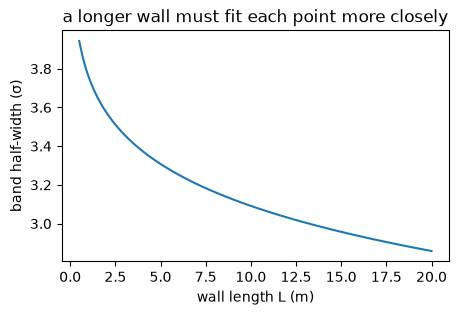

In [10]:
A_scan = np.ptp(P0[:, 0]) * np.ptp(P0[:, 1])


def band_halfwidth(A, L, sigma=SIGMA):
    return np.sqrt(2 * sigma ** 2 * np.log(A / (L * np.sqrt(2 * np.pi) * sigma)))


def gain(r, A, L, sigma=SIGMA):
    """Nats of evidence a point at distance r brings to the line (negative: clutter explains it better)."""
    return np.log(A / (L * np.sqrt(2 * np.pi) * sigma)) - r ** 2 / (2 * sigma ** 2)


print(f"A = {A_scan:.1f} m²;  L = 4 m:  band = ±{band_halfwidth(A_scan, 4.0) * 100:.1f} cm "
      f"= {band_halfwidth(A_scan, 4.0) / SIGMA:.2f} σ;  a point on the line brings {gain(0, A_scan, 4.0):.2f} nats")
Ls = np.linspace(0.5, 20, 100)
plt.figure(figsize=(5, 3))
plt.plot(Ls, band_halfwidth(A_scan, Ls) / SIGMA)
plt.xlabel("wall length L (m)"); plt.ylabel("band half-width (σ)")
plt.title("a longer wall must fit each point more closely")

The band comes out at about $3\sigma$, close to what anyone would have picked by hand. The
derivation adds two things a tuned constant cannot:
- the band **narrows as $L$ grows**, because a long wall is a more expensive explanation of any
  one point;
- each point arrives with its evidence in **nats**, the currency every structural decision will
  be priced in.

### 4.4 Four walls

**Exercise 9.** For each Manhattan class $k = 0..3$, with normal angle $a_k = \theta_0 + k\pi/2$:
1. initialise $d_k$ as the median of $n(a_k)^\top p$ over the points whose normal is within 15° of
   $\pm a_k$ and which lie in front of the robot ($n^\top p > 0$);
2. refine $(\alpha, d)$ with a Laplace fit in which every point is weighted by its
   **responsibility** $w = \rho/(1+\rho)$, where $\rho$ is the density ratio. A point with weight
   $w$ enters with standard deviation $\sigma/\sqrt{w}$. Re-weight and refit a few times.

In [11]:
def line_residual(P):
    return lambda th: np.cos(th[0]) * P[:, 0] + np.sin(th[0]) * P[:, 1] - th[1]


def fit_wall(P, alpha, d, A, iters=5):
    L = 4.0
    for _ in range(iters):
        r = line_residual(P)([alpha, d])
        rho = A / (L * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
        w = rho / (1 + rho)
        use = w > 1e-3
        fit = laplace(line_residual(P[use]), [alpha, d], SIGMA / np.sqrt(w[use]))
        alpha, d = fit.belief.mu
        inl = P[w > 0.5]
        along = inl @ np.array([-np.sin(alpha), np.cos(alpha)])
        L = max(np.ptp(along), 0.5) if len(inl) > 2 else L   # the wall's observed length
    return fit.belief, w


walls = []
for k in range(4):
    a = theta0 + k * np.pi / 2
    n = np.array([np.cos(a), np.sin(a)])
    proj = Q0 @ n
    same_class = ok0 & (np.abs(se2.wrap(2 * (phi0 - a))) < np.deg2rad(30)) & (proj > 0)
    d0 = np.median(proj[same_class])
    belief, w = fit_wall(Q0, a, d0, A_scan)
    walls.append(belief)
    print(f"wall {k}: alpha = {np.degrees(belief.mu[0]):8.3f}° ± {np.degrees(belief.sd[0]):.3f}°,"
          f"  d = {belief.mu[1]:.3f} ± {belief.sd[1] * 1000:.1f} mm,  inliers {int((w > 0.5).sum())}")

wall 0: alpha =  -17.170° ± 0.157°,  d = 5.001 ± 5.0 mm,  inliers 31
wall 1: alpha =   72.800° ± 0.098°,  d = 3.400 ± 3.5 mm,  inliers 39
wall 2: alpha =  162.801° ± 0.119°,  d = 0.998 ± 2.3 mm,  inliers 107
wall 3: alpha =  252.821° ± 0.093°,  d = 0.601 ± 1.8 mm,  inliers 145


**Exercise 10.** The polygon is the walls intersected in cyclic order. Build it, map it into the
world with the grading-only `TRUE0`, and compute the IoU against the true living room.

IoU = 0.9939,  area 23.991 m² (truth 24)


Text(0.5, 1.0, 'the room, from one scan, in the map frame')

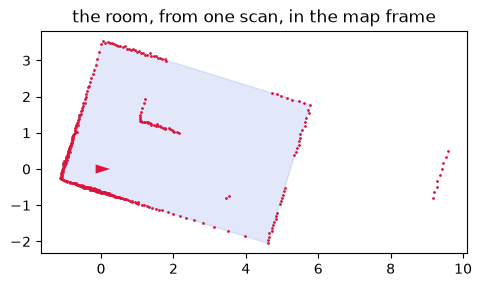

In [12]:
def intersect(w1, w2):
    A = np.array([[np.cos(w1.mu[0]), np.sin(w1.mu[0])], [np.cos(w2.mu[0]), np.sin(w2.mu[0])]])
    return np.linalg.solve(A, [w1.mu[1], w2.mu[1]])


room = np.array([intersect(walls[k], walls[(k + 1) % 4]) for k in range(4)])
truth_room = world.room("living").polygon
print(f"IoU = {polygon_iou(se2.transform_points(TRUE0, room), truth_room):.4f},  area {polygon_area(room):.3f} m² (truth 24)")

fig, ax = plt.subplots(figsize=(5.5, 4))
ax.plot(Q0[:, 0], Q0[:, 1], ".", ms=2, color="crimson")
ax.fill(*np.vstack([room, room[:1]]).T, fc="royalblue", alpha=0.15, ec="royalblue")
draw.robot([0, 0, 0], ax); ax.set_aspect("equal"); ax.set_title("the room, from one scan, in the map frame")

### 4.5 The price of a shape

Real rooms are not always four walls. The thesis prices every extra edge by **minimum
description length**. To transmit an edge you must say which of the four Manhattan directions it
takes ($\ln 4$ nats), and where its offset lies among $2R/c$ distinguishable positions, with $R$
the sensor range and $c$ the resolution:

$$ L_\text{edge} = \ln 4 + \ln(2R/c). $$

**Exercise 11.** Compute $L_\text{edge}$ for $R = 12$ m and $c = 5$ cm. Then compute the evidence
the **table's south face** would bring if it were proposed as a wall: the sum of `gain(r)` over the
points on it (use the true labels this once). Does the MDL price stop the table from becoming a
wall?

In [13]:
L_edge = np.log(4) + np.log(2 * 12.0 / 0.05)
table_pts = P0[scan0.labels[scan0.hit] == "table"]
face = laplace(line_residual(table_pts), [theta0 + np.pi / 2, np.median(table_pts @ [-np.sin(theta0), np.cos(theta0)])], SIGMA)
r_face = line_residual(table_pts)(face.belief.mu)
evidence = gain(r_face, A_scan, 1.2).clip(min=0).sum()
print(f"L_edge = {L_edge:.2f} nats;  the table face would earn {evidence:.0f} nats from {len(table_pts)} points")

L_edge = 7.56 nats;  the table face would earn 82 nats from 34 points


**Question.** The table face pays the MDL price many times over, so the price cannot be what
keeps furniture out of the room's outline. What evidence *does* tell a table face from a wall?

*Answer.* **Free space.** Beams pass beside and beyond the table and hit the real wall behind it,
so the region behind the "wall" is observed to be empty. A room is a region the robot can see
into, not just a set of surfaces. That is why the thesis draws the outline from a grid that
counts, per cell, the beams that pass through as well as the beams that stop, and why free floor
beyond an edge counts as evidence against that edge.

## 5. Localising in the room (in class: Exercise 12)

Now the room is a constant (the operating regime) and the robot drives. Each step has two
parts:
- **Predict.** `predict(belief, odometry)` pushes the encoder and gyro noise through the motion
  Jacobian. No constant process noise is added.
- **Correct.** A Laplace fit of the scan against the room, with the prediction as the prior. The
  residual of each scan point is its distance to the nearest wall: the localiser's
  distance field.

**Exercise 12.** Write the pose residual: map the robot-frame points through a candidate pose $X$,
then take their distance to the polygon.

rms error: x 2.2 mm, y 1.0 mm, theta 0.036°


Text(0.5, 1.0, 'localising against the estimated room (ellipses ×20)')

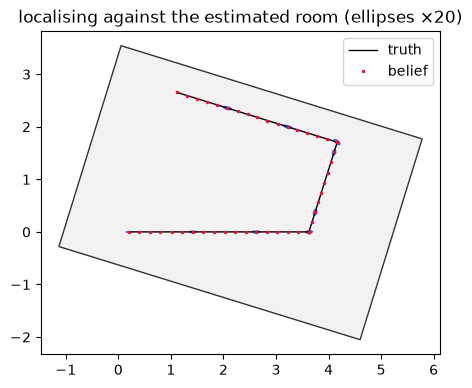

In [14]:
# the room in the map frame: the one you built in section 4, or the true one if you skipped it
truth_room = world.room("living").polygon
try:
    room
except NameError:
    room = se2.to_frame(TRUE0, truth_room)


def pose_residual(P_robot, polygon):
    return lambda X: distance_to_polygon(se2.transform_points(X, P_robot), polygon)


def localise(prior, P_robot, polygon, iters=3):
    A, x = polygon_area(polygon), prior.mu.copy()
    for _ in range(iters):
        r = pose_residual(P_robot, polygon)(x)
        rho = A / (20.0 * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
        w = rho / (1 + rho)
        use = w > 1e-3
        fit = laplace(pose_residual(P_robot[use], polygon), x, SIGMA / np.sqrt(w[use]), prior=prior)
        x = fit.belief.mu
    return fit.belief


turn_to_north = [(0.0, (np.pi / 2 - 0.3) / 2.5)] * 5
turn_left = [(0.0, np.pi / 6)] * 6
COMMANDS = [(0.4, 0.0)] * 18 + turn_to_north + [(0.4, 0.0)] * 9 + turn_left + [(0.4, 0.0)] * 16


def drive(polygon, seed, commands=COMMANDS, scans=True):
    """Run the filter along the route. Returns the true poses (map frame) and the beliefs."""
    r = np.random.default_rng(seed)
    robot = Robot(TRUE0.copy(), Body(), r)
    belief = Gaussian([0, 0, 0], np.diag([1e-9] * 3))
    truths, beliefs = [], []
    for v, w in commands:
        belief = predict(belief, robot.step(v, w, 0.5))
        assert world.room_of(robot.pose[:2]) == "living", "the route left the room!"
        if scans:
            belief = localise(belief, lidar.scan(world, robot.pose, r).points(), polygon)
        truths.append(se2.ominus(robot.pose, TRUE0))
        beliefs.append(belief)
    return np.array(truths), beliefs


def nees(truths, beliefs):
    out = []
    for t, b in zip(truths, beliefs):
        e = t - b.mu
        e[2] = se2.wrap(e[2])
        out.append(e @ np.linalg.solve(b.Sigma, e))
    return np.array(out)


truths, beliefs = drive(room, seed=1)
err = np.array([t - b.mu for t, b in zip(truths, beliefs)])
print(f"rms error: x {np.sqrt((err[:, 0] ** 2).mean()) * 1000:.1f} mm, y {np.sqrt((err[:, 1] ** 2).mean()) * 1000:.1f} mm, "
      f"theta {np.degrees(np.sqrt((err[:, 2] ** 2).mean())):.3f}°")

fig, ax = plt.subplots(figsize=(6, 4.2))
ax.fill(*np.vstack([room, room[:1]]).T, fc="0.95", ec="0.2")
ax.plot(truths[:, 0], truths[:, 1], "k-", lw=1, label="truth")
mus = np.array([b.mu for b in beliefs])
ax.plot(mus[:, 0], mus[:, 1], ".", color="crimson", ms=3, label="belief")
for b in beliefs[::6]:
    draw.covariance(b.mu, b.Sigma * 400, ax)   # 2σ ellipses, ×20 so they are visible
ax.set_aspect("equal"); ax.legend(); ax.set_title("localising against the estimated room (ellipses ×20)")

**Is the belief's spread right?** The normalised estimation error squared (NEES),
$e^\top\Sigma^{-1}e$, averages to the state dimension (3) when the covariance is right. It is
larger when the belief is over-confident, and smaller when it is pessimistic.

**Exercise 13.** Compute the mean NEES over 4 seeds for three maps:
- the true polygon;
- the one-scan estimate from section 4 (or the true room again, if you skipped it);
- the true polygon with its east wall moved 1.5 cm.

In [15]:
true_room = se2.to_frame(TRUE0, truth_room)
bad_room = true_room.copy()
east = np.argsort(true_room @ np.array([np.cos(-0.3), np.sin(-0.3)]))[-2:]   # the two east corners
bad_room[east] += 0.015 * np.array([np.cos(-0.3), np.sin(-0.3)])
for name, poly in (("true room", true_room), ("estimated (sec. 4)", room), ("east wall +1.5 cm", bad_room)):
    score = np.mean([nees(*drive(poly, seed)).mean() for seed in range(4)])
    print(f"{name:20s} mean NEES = {score:6.2f}   (3 = right)")

true room            mean NEES =   1.95   (3 = right)


estimated (sec. 4)   mean NEES =   3.81   (3 = right)


east wall +1.5 cm    mean NEES =  89.84   (3 = right)


**Lesson.** A wall 1.5 cm out of place makes the localiser **confidently wrong**: its error
grows to several of its own standard deviations, and nothing inside the localiser notices. The
polygon is a *constant* in the operating regime. It contributes no uncertainty, so its errors are
shared by every scan, forever. That is the price of the regime split, and it is why the thesis
says the operating regime "cannot detect that the polygon it was given is wrong". Something
else, the acquisition regime, must be right, or know when it is not.

## 6. The room's symmetry (optional)

A 6 × 4 m rectangle looks the same after a half-turn about its centre. Take the robot's final
scan and evaluate the Laplace free energy at the true pose and at its half-turn image, with a weak
prior and no odometry.

**Exercise 14.** Compute both $F$ values.

In [16]:
r_ = np.random.default_rng(7)
X_true = truths[-1]
P_last = lidar.scan(world, se2.compose(TRUE0, X_true), r_).points()
centre = true_room.mean(axis=0)
X_flip = np.array([*(2 * centre - X_true[:2]), se2.wrap(X_true[2] + np.pi)])
for name, X0 in (("true pose", X_true), ("half-turn", X_flip)):
    b = localise(Gaussian(X0, np.diag([1.0, 1.0, 1.0])), P_last, true_room)
    r = pose_residual(P_last, true_room)(b.mu)
    rho = polygon_area(true_room) / (20 * np.sqrt(2 * np.pi) * SIGMA) * np.exp(-r ** 2 / (2 * SIGMA ** 2))
    w = rho / (1 + rho)
    F = laplace(pose_residual(P_last[w > 1e-3], true_room), b.mu, SIGMA / np.sqrt(w[w > 1e-3]),
                prior=Gaussian(X0, np.eye(3))).free_energy
    print(f"{name:10s} pose {np.round(b.mu, 3)}   F = {F:.2f} nats")

true pose  pose [1.11  2.657 2.84 ]   F = -786.82 nats
half-turn  pose [ 3.539 -1.164 -0.302]   F = -786.82 nats


**Questions.**
- The two free energies differ by a fraction of a nat. No gradient connects the two poses, so
  descent cannot choose between them. What must?
- The table and the door gap are *not* symmetric. Why don't they break the tie here?

*Answers.*
- The choice is **discrete**, so it needs a discrete search plus evidence the room cannot
  provide: continuity with the previous pose (the motion prior), or a landmark that is not
  symmetric. The thesis's localiser searches the room's symmetries explicitly. That is one of the
  few places where a threshold is the right design, because a continuous relaxation of a
  discrete choice is not a better model of it.
- Because the **model** does not contain them. Our polygon has no door gap, and the table's
  points are classed as clutter. Evidence the model throws away cannot break a tie. The thesis
  later uses the fridge as a room landmark for exactly this purpose.

## 7. The common-mode ceiling (optional)

Before there is a room to localise against, the robot only has odometry, and its pose
uncertainty grows. Suppose it maps the **table's south face** from there, using a dense sensor
(think: a camera mask with thousands of pixels). Each point's map position is
$p_\text{map} = X \oplus p_\text{robot}$, so every point inherits the **same** pose error.

Marginalising that shared error gives the information one frame can carry:

$$ \mathcal I = J^\top(\sigma^2 I + J_X\Sigma_X J_X^\top)^{-1}J
   \;\overset{\text{Woodbury}}{\Longrightarrow}\;
   \operatorname{var}(\hat y) = \frac{\sigma^2}{N} + j^\top \Sigma_X\, j
   \;\xrightarrow[N\to\infty]{}\; j^\top\Sigma_X j \neq 0, $$

where $j = \partial y_\text{map} / \partial X$, averaged over the points.

**Exercise 15.** Over 60 runs, dead-reckon the first leg, estimate the face's offset along its normal from
$N$ = 1 … 32 points, and compare the true rms error with two predictions: independent points
only (with Day 2's per-point $\sigma_i = \sigma|u_i^\top n|$), and the Woodbury formula.

N=  1  actual   8.82 mm   independent   4.92   Woodbury   9.29
N=  2  actual   7.44 mm   independent   3.54   Woodbury   8.47
N=  4  actual   7.49 mm   independent   2.50   Woodbury   8.02
N=  8  actual   7.15 mm   independent   1.78   Woodbury   7.74
N= 16  actual   6.69 mm   independent   1.25   Woodbury   7.64
N= 32  actual   6.57 mm   independent   0.89   Woodbury   7.58


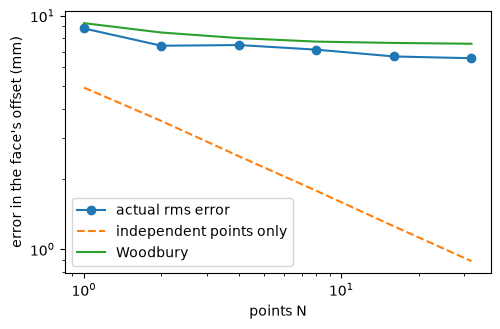

In [17]:
dense = Lidar(n_beams=2880, sigma=SIGMA)
Ns = [1, 2, 4, 8, 16, 32]
rows = {N: [] for N in Ns}
for seed in range(60):
    r_ = np.random.default_rng(seed)
    _, bs = drive(true_room, seed, COMMANDS[:18], scans=False)   # odometry only
    b = bs[-1]
    robot_pose = se2.compose(TRUE0, _[-1])
    s = dense.scan(world, robot_pose, r_)
    on_table = s.labels[s.hit] == "table"
    true_pts = np.stack([np.cos(s.angles), np.sin(s.angles)], 1)[s.hit] * s.true_ranges[s.hit, None]
    on_face = on_table & (np.abs(se2.transform_points(robot_pose, true_pts)[:, 1] - 2.2) < 1e-6)  # grading
    P_face = s.points()[on_face]
    for N in Ns:
        idx = r_.choice(len(P_face), N, replace=False)
        pts_map = se2.transform_points(b.mu, P_face[idx])
        n_face = np.array([-np.sin(-0.3), np.cos(-0.3)])             # the face's normal, map frame
        d_true = se2.to_frame(TRUE0, np.array([[2.2, 2.2]]))[0] @ n_face
        err = (pts_map @ n_face).mean() - d_true                     # what the robot would report, minus truth
        th = b.mu[2]
        dp_dth = np.stack([-np.sin(th) * P_face[idx, 0] - np.cos(th) * P_face[idx, 1],
                           np.cos(th) * P_face[idx, 0] - np.sin(th) * P_face[idx, 1]], 1)
        j = np.array([n_face[0], n_face[1], (dp_dth @ n_face).mean()])  # ∂(offset)/∂(x, y, θ)
        u = P_face[idx] / np.linalg.norm(P_face[idx], axis=1, keepdims=True)     # beam directions, robot frame
        u_map = u @ se2.rot(th).T
        sig_i = SIGMA * np.abs(u_map @ n_face)                       # Day 2: noise along the beam, seen along the normal
        var_indep = np.sum(sig_i ** 2) / N ** 2
        rows[N].append((err, np.sqrt(var_indep), np.sqrt(var_indep + j @ b.Sigma @ j)))

rms = [np.sqrt(np.mean([e ** 2 for e, _, _ in rows[N]])) for N in Ns]
naive = [np.mean([n for _, n, _ in rows[N]]) for N in Ns]
wood = [np.mean([w for _, _, w in rows[N]]) for N in Ns]
plt.figure(figsize=(5.5, 3.4))
plt.loglog(Ns, np.array(rms) * 1000, "o-", label="actual rms error")
plt.loglog(Ns, np.array(naive) * 1000, "--", label="independent points only")
plt.loglog(Ns, np.array(wood) * 1000, "-", label="Woodbury")
plt.xlabel("points N"); plt.ylabel("error in the face's offset (mm)"); plt.legend()
for N, a, n_, w_ in zip(Ns, rms, naive, wood):
    print(f"N={N:3d}  actual {a * 1000:6.2f} mm   independent {n_ * 1000:6.2f}   Woodbury {w_ * 1000:6.2f}")

**Lesson.** Past a handful of points, more pixels buy nothing: the error stops at the pose
error, not at zero. A filter that kept counting points as independent would report
under a millimetre while being off by about seven. That is the over-confidence every concept agent in
the thesis must guard against, and the reason the agents carry this term explicitly.

## 8. Why the two regimes are kept apart (reading)

You have now run both regimes. A natural question is why not estimate the room and the pose
together all the time, as SLAM does. The thesis answers that a room changes over years and a pose
changes every cycle. Estimating them jointly at frame rate tracks a constant at great expense. So
the room is estimated jointly only until it is settled, and then handed over as a constant.

The thesis also keeps a loop from forming during acquisition. A wrong wall would drag the pose,
and the dragged pose would confirm the wrong wall. So the pose comes from plain scan-to-map SLAM,
which knows nothing about walls, and the outline is drawn from a map filled at that pose: the
outline depends on the pose, and never feeds back into it.
Exercise 13 is the small version of that lesson: **a factor inherits the errors of whatever it is
estimated through.**

## Action: setup

Parts I and J work in the living room with the pose known: the operating regime.

In [18]:
from toyworld import Gaussian, Grid, Lidar, Robot, draw, laplace, se2, two_room_apartment
from toyworld.beliefs import binary_entropy, linear_gaussian_update, numeric_jacobian, sigmoid
from toyworld.geometry import distance_to_polygon, point_in_polygon, polygon_area, segments_of
from toyworld.grid import expected_gain
from toyworld.robot import Body, hidden_body, integrate

world = two_room_apartment()
lidar = Lidar(n_beams=360, sigma=0.02, max_range=12.0)
SIGMA = 0.02
room = world.room("living").polygon     # today the room is given: the operating regime, world frame
START = np.array([1.0, 0.8, 0.0])

## 9. Where to look at one wall (in class: Exercises 16 and 18)

The smallest case of choosing a viewpoint: Day 2's north wall, held as a Laplace
belief after one scan. The cell below rebuilds that belief exactly as Day 2 left it (90° LiDAR,
known pose, ground-truth labels to pick the wall's points, per-beam incidence noise).

In [19]:
from toyworld import info_gain
from toyworld.geometry import point_segment_distance

rng_w = np.random.default_rng(0)
wall_lidar = Lidar(n_beams=90, fov=np.deg2rad(90), sigma=0.02)
oracle = Lidar(n_beams=90, fov=np.deg2rad(90), sigma=0.0)
pose0 = np.array([4.5, 1.0, np.deg2rad(110)])
NORTH = np.array([[[0.0, 4.0], [6.0, 4.0]]])


def wall_points(scan, wall=NORTH, tol=0.15):
    pts = se2.transform_points(scan.pose, scan.points())
    bearings = scan.pose[2] + scan.angles[scan.hit]
    on_wall = (scan.labels[scan.hit] == "wall") & (point_segment_distance(pts, wall)[:, 0] < tol)
    return pts[on_wall], bearings[on_wall]


def residual(pts):
    return lambda t: np.cos(t[0]) * pts[:, 0] + np.sin(t[0]) * pts[:, 1] - t[1]


def jacobian(pts):
    return lambda t: np.stack([-np.sin(t[0]) * pts[:, 0] + np.cos(t[0]) * pts[:, 1], -np.ones(len(pts))], axis=1)


def incidence_sigma(p, bearings, alpha=np.pi / 2):
    u = np.stack([np.cos(bearings), np.sin(bearings)], axis=1)
    return 0.02 * np.abs(u @ np.array([np.cos(alpha), np.sin(alpha)]))


pts0, bear0 = wall_points(wall_lidar.scan(world, pose0, rng_w))
wall0 = laplace(residual(pts0), [np.pi / 2, 4.0], incidence_sigma(pts0, bear0), jacobian=jacobian(pts0)).belief
print(f"Day 2's wall: alpha = {np.degrees(wall0.mu[0]):.3f}° ± {np.degrees(wall0.sd[0]):.3f}°,  d = {wall0.mu[1]:.4f} ± {wall0.sd[1]:.4f} m")

Day 2's wall: alpha = 89.906° ± 0.116°,  d = 4.0078 ± 0.0083 m


### 9.1 Information gain

At decision time the current scan has already happened, so $\partial F / \partial a = 0$.
Actions are scored by the free energy they are *expected* to produce. For a Gaussian belief and
a linear-Gaussian measurement, the epistemic part of the expected free energy is the expected
entropy drop, which equals the mutual information, which equals the D-optimal design criterion:

$$ \Delta H(v) = \tfrac12 \ln\frac{|\Lambda + J_v^\top R_v^{-1} J_v|}{|\Lambda|}. $$

`info_gain(Lambda, J, R)` computes this. To predict *which* points a viewpoint $v$ would see we
cheat: we ray-cast the true world (with zero noise). In section 10 the robot predicts it from its
own beliefs instead.

**Exercise 16.** Compute $\Delta H$ for each candidate below and rank them. Before running, guess
which wins.

stay here       sees  65 wall points   ΔH = 0.693 nats   distance 0.00 m
under the wall  sees  90 wall points   ΔH = 0.705 nats   distance 2.75 m
far west        sees  39 wall points   ΔH = 0.949 nats   distance 3.70 m
behind table    sees  14 wall points   ΔH = 0.543 nats   distance 2.33 m
east corner     sees  47 wall points   ΔH = 0.587 nats   distance 1.12 m


(-0.3, 4.4)

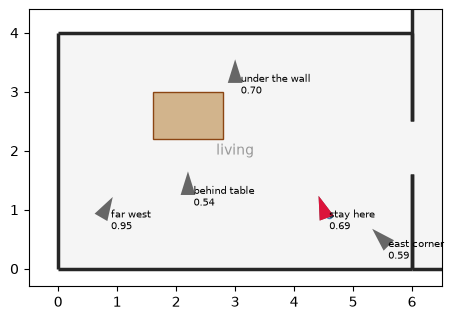

In [20]:
views = {
    "stay here":     [4.5, 1.0, np.deg2rad(110)],
    "under the wall": [3.0, 3.3, np.deg2rad(90)],
    "far west":      [0.8, 1.0, np.deg2rad(60)],
    "behind table":  [2.2, 1.4, np.deg2rad(90)],
    "east corner":   [5.5, 0.5, np.deg2rad(135)],
}


def predicted_gain(belief, view):
    s = oracle.scan(world, np.asarray(view), rng_w)
    p, b = wall_points(s)
    if len(p) == 0:
        return 0.0, 0
    J = jacobian(p)(belief.mu)
    R = np.diag(incidence_sigma(p, b, belief.mu[0]) ** 2)
    return info_gain(belief.precision, J, R), len(p)


fig, ax = plt.subplots(figsize=(9, 3.6))
draw.world(world, ax)
for name, v in views.items():
    g, n = predicted_gain(wall0, v)
    print(f"{name:15s} sees {n:3d} wall points   ΔH = {g:.3f} nats   distance {np.hypot(v[0] - pose0[0], v[1] - pose0[1]):.2f} m")
    draw.robot(v, ax, color="0.4"); ax.annotate(f"{name}\n{g:.2f}", v[:2], fontsize=7, xytext=(4, -14), textcoords="offset points")
draw.robot(pose0, ax); ax.set_xlim(-0.5, 6.5); ax.set_ylim(-0.3, 4.4)

**Questions.**
- "Stay here" gains almost exactly $\ln 2 = 0.693$ nats. Why that number?
- "Far west" sees *fewer* points than "under the wall" but gains more. Why?

*Answers.*
- A second identical scan doubles the information matrix: $|2\Lambda| / |\Lambda| = 2^2$ for a
  two-parameter belief, so $\Delta H = \tfrac12 \ln 4 = \ln 2$.
- The first scan saw the east part of the wall ($x \gtrsim 2$). The west end adds **lever arm**
  on the angle: points far from those already seen constrain $\alpha$ in a direction the current
  information matrix is weak in. Information depends on where the new data sit relative to what
  is already known, not on how many points there are.

**Exercise 17 (diminishing returns).** If the robot stays and scans again and again, what is the
$k$-th look worth? Compute it with `info_gain` and compare with $\ln\frac{k+1}{k}$.

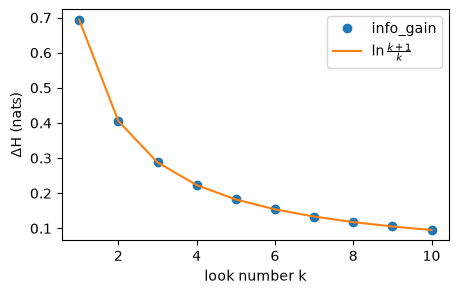

In [21]:
s = oracle.scan(world, pose0, rng_w)
p, b = wall_points(s)
J1 = jacobian(p)(wall0.mu)
R1 = np.diag(incidence_sigma(p, b) ** 2)
L1 = J1.T @ np.linalg.solve(R1, J1)   # the information in one look
ks = np.arange(1, 11)
gains = [info_gain(k * L1, J1, R1) for k in ks]
plt.figure(figsize=(5, 3))
plt.plot(ks, gains, "o", label="info_gain")
plt.plot(ks, np.log((ks + 1) / ks), "-", label=r"$\ln\frac{k+1}{k}$")
plt.xlabel("look number k"); plt.ylabel("ΔH (nats)"); plt.legend()

### 9.2 Paying for travel in the same currency

The expected free energy has a **pragmatic** term too. The simplest one is a preference for not
driving far: $G(v) = \beta\,\lVert v - x\rVert - \Delta H(v)$, with $\beta$ in nats per metre.

**Exercise 18.** For $\beta \in [0, 0.2]$ nats/m, which candidate minimises $G$? Find the $\beta$
at which the robot stops moving and simply scans again.

In [22]:
gains = {name: predicted_gain(wall0, v)[0] for name, v in views.items()}
dists = {name: np.hypot(v[0] - pose0[0], v[1] - pose0[1]) for name, v in views.items()}
for beta in np.linspace(0, 0.2, 21):
    G = {name: beta * dists[name] - gains[name] for name in views}
    best = min(G, key=G.get)
    print(f"beta = {beta:.2f} nats/m  ->  {best}")

beta = 0.00 nats/m  ->  far west
beta = 0.01 nats/m  ->  far west
beta = 0.02 nats/m  ->  far west
beta = 0.03 nats/m  ->  far west
beta = 0.04 nats/m  ->  far west
beta = 0.05 nats/m  ->  far west
beta = 0.06 nats/m  ->  far west
beta = 0.07 nats/m  ->  stay here
beta = 0.08 nats/m  ->  stay here
beta = 0.09 nats/m  ->  stay here
beta = 0.10 nats/m  ->  stay here
beta = 0.11 nats/m  ->  stay here
beta = 0.12 nats/m  ->  stay here
beta = 0.13 nats/m  ->  stay here
beta = 0.14 nats/m  ->  stay here
beta = 0.15 nats/m  ->  stay here
beta = 0.16 nats/m  ->  stay here
beta = 0.17 nats/m  ->  stay here
beta = 0.18 nats/m  ->  stay here
beta = 0.19 nats/m  ->  stay here
beta = 0.20 nats/m  ->  stay here


**Question (the key one of this part).** For any $\beta$ above about 0.07, the robot prefers to
stay and re-scan, because a repeat look is "worth" $\ln 2$ nats for free. What does the model
*assume* that makes the repeat look so valuable? Would that assumption hold on a real robot?

*Answer.* The value $\ln 2$ assumes the second scan's errors are **independent** of the first's.
On a real robot, both scans share the same pose error, the same sensor-mount error and the same
calibration error. Those common-mode errors do not average away, so the second look is worth far
less than $\ln 2$. Averaging removes independent error, not shared error. Day 4 put a number on
this (the common-mode ceiling). The robot's real layout explorer takes the opposite extreme: its
map keeps one point per voxel, so a repeat look adds nothing at all, and its "precision" term
turned out to be inert. What carries that explorer is credit for what a viewpoint can *resolve*,
not for how often it has been seen (post-thesis result, work in progress).

### 9.3 Go there and look (at home)

**Exercise 19.** Move to "far west", scan, and update the belief. The update is another Laplace
fit, with the current belief as the **prior**. Compare the realised entropy drop with the
prediction.

In [23]:
view = np.asarray(views["far west"])
s = wall_lidar.scan(world, view, rng_w)
p, b = wall_points(s)
fit1 = laplace(residual(p), wall0.mu, incidence_sigma(p, b, wall0.mu[0]), jacobian=jacobian(p), prior=wall0)
wall1 = fit1.belief
print(f"predicted ΔH = {gains['far west']:.3f} nats,  realised ΔH = {wall0.entropy() - wall1.entropy():.3f} nats")
print(f"alpha sd: {np.degrees(wall0.sd[0]):.4f}° -> {np.degrees(wall1.sd[0]):.4f}°")

predicted ΔH = 0.949 nats,  realised ΔH = 0.951 nats
alpha sd: 0.1155° -> 0.0568°


Prediction and realisation agree because the problem is close to linear. Note *what* agreed:
the entropy drop of a Gaussian depends on **where** you look, not on **what** you see, so it can
be computed before the robot moves. That is what makes an expected free energy computable.

## 10. Priced offers on the shared graph (at home)

Section 9 let one belief choose. A real robot has many beliefs, and a single body to serve them. Each
concept agent knows what *it* would gain from a look; only the controller knows what a trip costs.
So the agents publish **offers** in the shared graph and the controller compares them. No agent
calls another. The currency is the nat.

- A **producer** owns what view it wants, *expressed relative to its object*, what that view is
  worth, and when it has learnt enough.
- The **executor** owns feasibility, the cost of getting there, and which offer wins.

The toy: two objects with position beliefs and a sensor that measures range well and bearing badly,
so *where you stand* decides which direction you learn. A door offers a **pragmatic** value: nothing
to learn, but the robot's task is to end up there.

### 10.1 What a view is worth

Pointing the sensor from viewpoint $c$ at an object believed at $\mu$, with $u$ the unit vector
from $c$ to $\mu$ and $r$ the distance, gives a position measurement with
$R = \sigma_r^2\,uu^\top + (\sigma_b r)^2\,u_\perp u_\perp^\top$. But a detector also has to
*fire*. The fraction of the image the object fills is $f = \text{size}/(2r)$, and the thesis models
detection as a soft band,

$$ P(\text{detect}\mid c) = \mathrm{sigm}\!\Big(\frac{f-f_{\min}}{w}\Big)\,\mathrm{sigm}\!\Big(\frac{f_{\max}-f}{w}\Big), $$

too small to segment on one side, truncated on the other.

**Exercise 20.** Write `view_gain`: the expected entropy drop of one look,
$\mathbb E[\Delta H] = P(\text{detect})\cdot\tfrac12\ln\big(|\Lambda+R^{-1}|/|\Lambda|\big)$.

In [24]:
from toyworld import Graph

F_MIN, F_MAX, F_W = 0.10, 0.60, 0.06       # the thesis's envelope: a prior, not a measurement
SIGMA_R, SIGMA_B = 0.02, 0.03              # range sd (m), bearing sd (rad)


def p_detect(f):
    return sigmoid((f - F_MIN) / F_W) * sigmoid((F_MAX - f) / F_W)


def sensor_R(c, mu):
    d = np.asarray(mu) - np.asarray(c)
    r = np.hypot(*d)
    u, n = d / r, np.array([-d[1], d[0]]) / r
    return SIGMA_R ** 2 * np.outer(u, u) + (SIGMA_B * r) ** 2 * np.outer(n, n)


def view_gain(belief, c, size):
    r = np.hypot(*(np.asarray(c) - belief.mu))
    return p_detect(size / (2 * r)) * info_gain(belief.precision, np.eye(2), sensor_R(c, belief.mu))

### 10.2 A producer writes to the graph

`Producer` below is a concept agent in miniature. It owns a node for its object and, while it still
wants something, a child node of type `affordance` holding a ranked list of offers. An offer says
"from this bearing and stand-off, relative to my object, a look is worth this many nats". It does
*not* name a world pose: the producer cannot know a table is in the way. When the belief meets
its **precision demand** $\Sigma^\ast$, the producer removes its own offer.

Read it. Nothing is hidden in it, and nothing in it mentions any other agent.

In [25]:
BEARINGS = np.deg2rad(np.arange(0, 360, 45))
FILLS = (0.15, 0.30, 0.50)                 # the stand-off band, as image fills


class Producer:
    def __init__(self, g, name, size, mu, sd, demand=0.025, truth=None):
        self.g, self.name, self.size, self.demand = g, name, size, demand
        self.belief = Gaussian(mu, np.eye(2) * sd ** 2)
        self.truth = np.asarray(truth, float)
        self.owner = name + "_agent"
        g.add_node(name, "object", parent="living", pose=[*self.belief.mu, 0.0], owner=self.owner)
        g.add_node("aff_" + name, "affordance", parent=name, owner=self.owner, offers=[], pragmatic=0.0)
        self.withdrawn = False
        self.publish()

    def publish(self):
        if self.withdrawn:
            return
        if np.sqrt(np.linalg.eigvalsh(self.belief.Sigma).max()) <= self.demand:     # Σ* reached
            self.g.remove("aff_" + self.name)
            self.withdrawn = True
            return
        offers = []
        for bearing in BEARINGS:
            for f in FILLS:
                standoff = self.size / (2 * f)
                c = self.belief.mu + standoff * np.array([np.cos(bearing), np.sin(bearing)])
                offers.append(dict(bearing=bearing, standoff=standoff, gain=view_gain(self.belief, c, self.size)))
        self.g.update("aff_" + self.name, offers=sorted(offers, key=lambda o: -o["gain"]))
        self.g.set_rt("living", self.name, [*self.belief.mu, 0.0], np.diag([*np.diag(self.belief.Sigma), 0.0]))

    def observe(self, x, rng):
        """One look from x. A miss teaches nothing about position."""
        r = np.hypot(*(x - self.truth))
        if rng.random() < p_detect(self.size / (2 * r)):
            R = sensor_R(x, self.truth)
            y = rng.multivariate_normal(self.truth, R)
            self.belief = linear_gaussian_update(self.belief, np.eye(2), R, y)
        self.publish()

### 10.3 The controller reads offers and chooses

The executor sees only the graph. For each offer it resolves the object-relative request into a
standpoint, tests it against what only *it* knows (the room polygon and the footprint), and scores

$$ G = \lambda\,\text{dist} - \mathbb E[\Delta H] - \text{pragmatic}, \qquad \lambda = 0.2\ \text{nats/m}. $$

The offer in hand is re-scored with everything else, every cycle. A challenger takes over only if
it is better by more than a **switching margin** $m$, the price of abandoning work under way.

**Exercise 21.** Complete `select`: score every feasible offer, find the best, and apply the margin.

In [26]:
LAMBDA, MARGIN, CLEAR = 0.2, 0.5, 0.3
TABLE_OUTLINE = world.things[0].outline()


def feasible(c):
    c = np.asarray(c)[None]
    in_room = point_in_polygon(c, room)[0] and distance_to_polygon(c, room)[0] >= CLEAR
    return bool(in_room and not point_in_polygon(c, TABLE_OUTLINE)[0] and distance_to_polygon(c, TABLE_OUTLINE)[0] >= CLEAR)


def resolve(g, aff):
    """Every feasible standpoint of an affordance, as (standpoint, gain)."""
    centre = g.world_pose(g.parent(aff.id))[:2]
    out = []
    for o in aff.attrs["offers"]:
        c = centre + o["standoff"] * np.array([np.cos(o["bearing"]), np.sin(o["bearing"])])
        if feasible(c):
            out.append((c, o["gain"]))
    return out


def select(g, x, incumbent):
    """Returns (affordance name or None, standpoint, G of that choice, the scores of this cycle)."""
    scores = {}
    for aff in g.by_type("affordance"):
        best = None
        for c, gain in resolve(g, aff):
            G = LAMBDA * np.hypot(*(c - x)) - gain - aff.attrs["pragmatic"]
            if best is None or G < best[0]:
                best = (G, c)
        if best is not None:
            scores[aff.name] = best
    if not scores:
        return None, None, 0.0, scores
    name = min(scores, key=lambda n: scores[n][0])
    if incumbent in scores and scores[name][0] > scores[incumbent][0] - MARGIN:
        name = incumbent
    return name, scores[name][1], scores[name][0], scores

### 10.4 Run it

Each cycle the controller selects, the robot moves up to 0.4 m towards the chosen standpoint in a
straight line (routes are in `day4_extra.ipynb`), and the camera, pointed at the object of the offer
being served, takes one look at whatever falls within ±45° of that direction. The door's offer is one standpoint
in front of it, worth 1.0 nat of preference. Reaching it ends the run.

**Exercise 22.** Run the loop. Then, in one plot, trace each affordance's best $\mathbb E[\Delta H]$
against the cycle, and mark who held the robot on each cycle. Find the moment each hand-off happens.
What in the code decided it?

who held the robot: B B B T B B B B T T T D D D D D D
table   error 0.7 cm   sd max 2.3 cm   offer withdrawn: True
bottle  error 1.8 cm   sd max 1.9 cm   offer withdrawn: True
graph at the end:
world [root]
  living [room]
    table [object] (table_agent)
    bottle [object] (bottle_agent)
    door [object] (door_agent)
      aff_door [affordance] (door_agent)


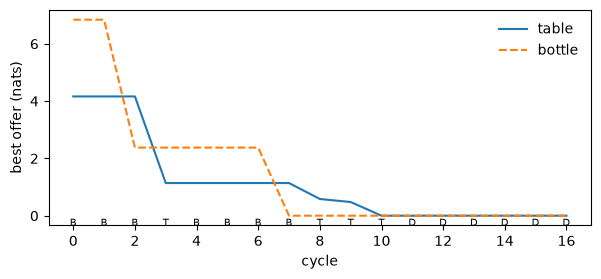

In [27]:
def run_offers(seed=0, lam=None, margin=None, door_value=1.0, max_cycles=60):
    global LAMBDA, MARGIN
    saved = LAMBDA, MARGIN
    LAMBDA, MARGIN = saved[0] if lam is None else lam, saved[1] if margin is None else margin
    rng_ = np.random.default_rng(seed)
    g = Graph()
    g.add_node("living", "room", parent="world")
    table_t, bottle_t = world.things[0], world.things[1]
    prods = [Producer(g, "table", 1.2, table_t.pose[:2] + [0.25, -0.2], 0.30, truth=table_t.pose[:2]),
             Producer(g, "bottle", 0.2, bottle_t.pose[:2] + [-0.3, 0.3], 0.50, truth=bottle_t.pose[:2])]
    g.add_node("door", "object", parent="living", pose=[5.5, 2.05, 0.0], owner="door_agent")
    g.add_node("aff_door", "affordance", parent="door", owner="door_agent",
               offers=[dict(bearing=0.0, standoff=0.0, gain=0.0)], pragmatic=door_value)
    x, incumbent, trace = START[:2].copy(), None, []
    for t in range(max_cycles):
        name, c, G, scores = select(g, x, incumbent)
        if name is None or G >= 0:
            break
        step = c - x
        if np.hypot(*step) > 0.4:
            step *= 0.4 / np.hypot(*step)
        x = x + step
        aim = g.world_pose(g.parent(g.node(name).id))[:2] - x      # the camera looks at the held object
        heading = np.arctan2(aim[1], aim[0])
        for p in prods:
            to_obj = p.truth - x
            if abs(se2.wrap(np.arctan2(to_obj[1], to_obj[0]) - heading)) <= np.pi / 4:
                p.observe(x, rng_)
            else:
                p.publish()
        trace.append(dict(t=t, holder=name, x=x.copy(), G=G,
                          **{p.name: (0.0 if p.withdrawn else g.node("aff_" + p.name).attrs["offers"][0]["gain"]) for p in prods},
                          sd=[np.sqrt(np.linalg.eigvalsh(p.belief.Sigma).max()) for p in prods]))
        incumbent = name
        if name == "aff_door" and np.hypot(*(x - c)) < 1e-6:
            break
    LAMBDA, MARGIN = saved
    return g, prods, trace


g_offers, prods_offers, trace = run_offers()
holders = [tr["holder"] for tr in trace]
print("who held the robot:", " ".join(h.replace("aff_", "")[0].upper() for h in holders))
for p in prods_offers:
    e = np.hypot(*(p.belief.mu - p.truth))
    print(f"{p.name:7s} error {e * 100:.1f} cm   sd max {np.sqrt(np.linalg.eigvalsh(p.belief.Sigma).max()) * 100:.1f} cm   offer withdrawn: {p.withdrawn}")
print("graph at the end:\n" + repr(g_offers))

fig, ax = plt.subplots(figsize=(7, 2.8))
ts = [tr["t"] for tr in trace]
ax.plot(ts, [tr["table"] for tr in trace], "-", label="table")
ax.plot(ts, [tr["bottle"] for tr in trace], "--", label="bottle")
for t, h in zip(ts, holders):
    ax.text(t, -0.35, h.replace("aff_", "")[0].upper(), ha="center", fontsize=7)
ax.set_xlabel("cycle"); ax.set_ylabel("best offer (nats)"); ax.legend(frameon=False)

**Questions.**
- Nothing in `select` says "the table is done, go to the bottle". What makes the robot move on?
- Re-run with `lam=1.0`, and separately with `margin=0.0`. What changes?
- Suppose the bottle's producer published a *world* pose instead of a bearing and a stand-off. What
  could the controller no longer do?

*Answers.*
- Looking shrinks the covariance that priced the look. An offer loses value by succeeding, and at
  some cycle another offer is better by more than the margin. The hand-off is a consequence of the
  values, and no rule was written for it. The withdrawal at $\Sigma^\ast$ is the producer's own decision
  about its own belief.
- At $\lambda = 1$ nat/m nothing across the room is worth the trip: the robot stops after a few
  cycles with both beliefs unfinished and never reaches the door. That is a legitimate answer: "not
  worth it". With no margin the number of hand-offs barely changes here; what changes is that the
  door overtakes the table's last small gain, and in most seeds the robot leaves with the table's
  offer still open. The margin's job is to finish what was started.
- Negotiate. A world pose may be infeasible and leaves no vocabulary to say so. An object-relative
  request has many resolutions, and the executor can pick one it can actually reach. The thesis puts
  the split of knowledge in those words.

## Today's lesson

A belief is born, kept and removed by comparisons in nats, it stands on a room and a pose whose
shared errors no number of points can average away, and it offers the robot what a look would teach
it, in the same nats. Choosing between offers needed nothing but that one currency.